# Plated in Gold, Part II: from asking to selling

Part I studied asking prices in a one-time snapshot of web-scraped Apple Watch listings. This notebook works through
Part II: a week of eBay listings tracked through the eBay Browse API until they ended, so that what sold, for how much
and how fast can be measured directly. It runs on the de-identified tables in `data/public/` and reproduces every
number in the README.

## 1. Setup

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display
from src import data as D, analysis as A, models as M, visualization as V, story
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
import io, matplotlib.figure
def _png(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight", facecolor="white", dpi=90)
    return buf.getvalue()
get_ipython().display_formatter.formatters["image/png"].for_type(matplotlib.figure.Figure, _png)
r = story.load(refresh=True)

## 2. The data

The collector ran from October 19 to October 26, 2026, with three gaps. `data/public/listings.csv.gz` has one row
per listing with its last observed state, the first observed price, the outcome and title-derived features.
Seller names are replaced by salted hashes and listing IDs by random keys.

In [2]:
ov = r["overview"]
pd.Series({k: v for k, v in ov.items() if not isinstance(v, (dict, list))})

listings                              31498
snapshots                            458087
outcomes                               3843
api_calls                             20399
sweeps                                    7
sweep_items_min                       24992
sweep_items_max                       26637
start                     2026-10-19T18:01Z
end                       2026-10-26T18:15Z
window_hours                     168.233333
gap_hours                             51.08
covered_share                      0.696374
sellers                               20109
detail_share                       0.305734
brand_missing_share                0.593403
single_watch                          30441
analysis_listings                     28214
lots                                    632
accessories                             343
other                                   116
no_model                               1130
price_outliers                          868
gold                            

,start,end,hours
0,2026-10-19 18:25:00+00:00,2026-10-19 21:00:00+00:00,2.58
1,2026-10-20 00:10:00+00:00,2026-10-20 13:27:00+00:00,13.28
2,2026-10-21 03:41:00+00:00,2026-10-22 14:54:00+00:00,35.22


active             27655
sold                2063
ended_unknown       1386
unsold               385
reserve_not_met        9
Name: listings, dtype: int64

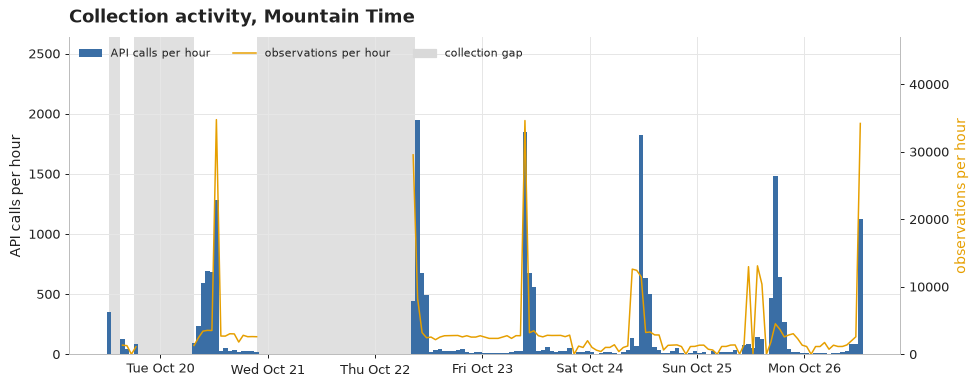

In [3]:
display(D.gaps())
display(pd.Series(ov["outcome_counts"], name="listings"))
V.fig_collection_timeline()

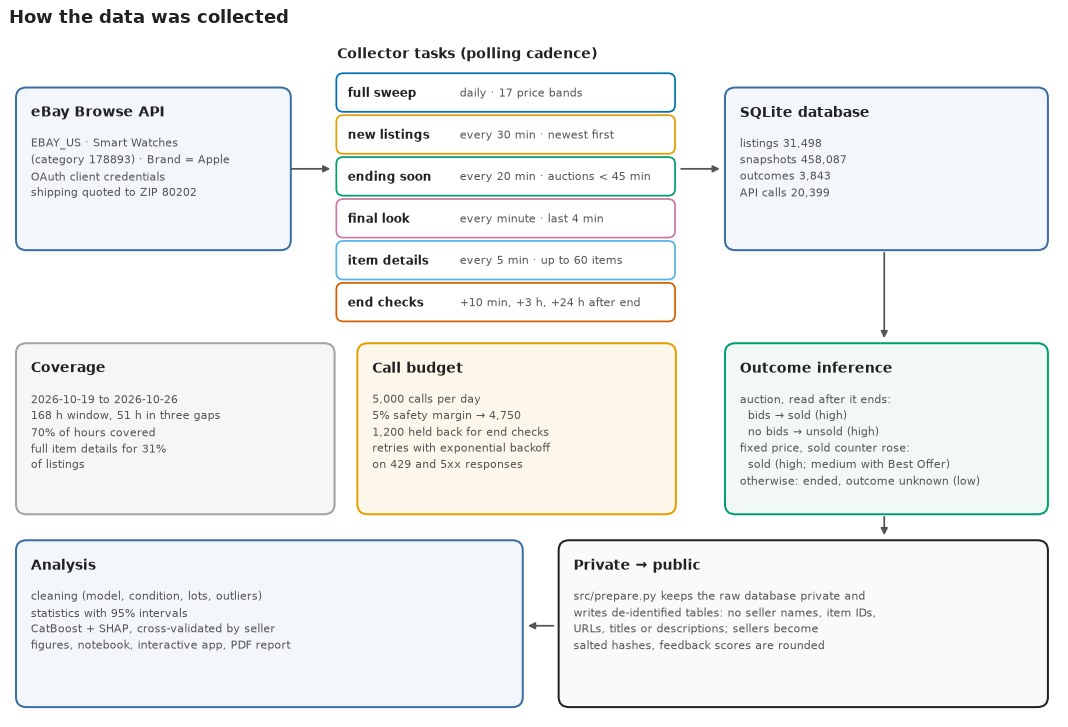

In [4]:
V.fig_pipeline(ov)

Outcome inference: an ended auction with bids is sold, one without bids is unsold; a fixed-price listing whose
`sold_quantity` counter rose is sold (medium confidence when Best Offer was on, because the accepted price is not
public); anything else that ended is `ended_unknown` and is never counted as a sale. Two auctions that ended with
no bids but a higher sold counter sold through Buy It Now or an offer, and are reclassified as sold.

In [5]:
d = D.listings()
d[["model", "condition_group", "format", "price", "outcome", "final_price", "gold", "age_years"]].sample(6, random_state=1)

,model,condition_group,format,price,outcome,final_price,gold,age_years
24892,Series 6,Used,Fixed price + Best Offer,80.0,active,NaN,0,0.052177
28255,Series 9,Used,Fixed price + Best Offer,219.0,ended_unknown,NaN,0,0.009879
28525,Series 11,Used,Fixed price,299.0,active,NaN,0,0.024352
18463,Series 10,Used,Fixed price,240.0,active,NaN,0,0.840779
18610,SE 3,Used,Fixed price + Best Offer,167.5,active,NaN,0,0.107172
3806,Ultra 2,New,Fixed price,2499.0,active,NaN,0,2.050901


## 3. Asking is not selling

,model,n_ask,n_sold,ask,sold,sold_lo,sold_hi,ratio,ratio_lo,ratio_hi
0,Series 2,438,12,62.99,39.50,24.72,50.00,1.59,1.20,2.60
1,Series 3,2284,81,75.00,35.00,32.00,39.00,2.14,1.88,2.34
2,Series 4,1018,50,89.00,45.25,40.00,50.00,1.97,1.70,2.25
3,Series 5,1252,51,100.00,56.99,49.99,60.00,1.75,1.67,2.00
4,Series 6,1323,80,119.95,65.00,61.00,69.99,1.85,1.70,1.92
5,Series 7,1427,121,140.00,80.75,77.99,86.00,1.73,1.60,1.86
6,Series 8,891,81,164.99,100.00,94.95,105.00,1.65,1.53,1.77
7,Series 9,699,107,200.00,130.00,125.99,138.00,1.54,1.44,1.59
8,Series 10,649,111,245.00,180.00,175.00,199.00,1.36,1.23,1.41
9,Series 11,404,80,277.00,230.00,228.74,240.00,1.20,1.13,1.23


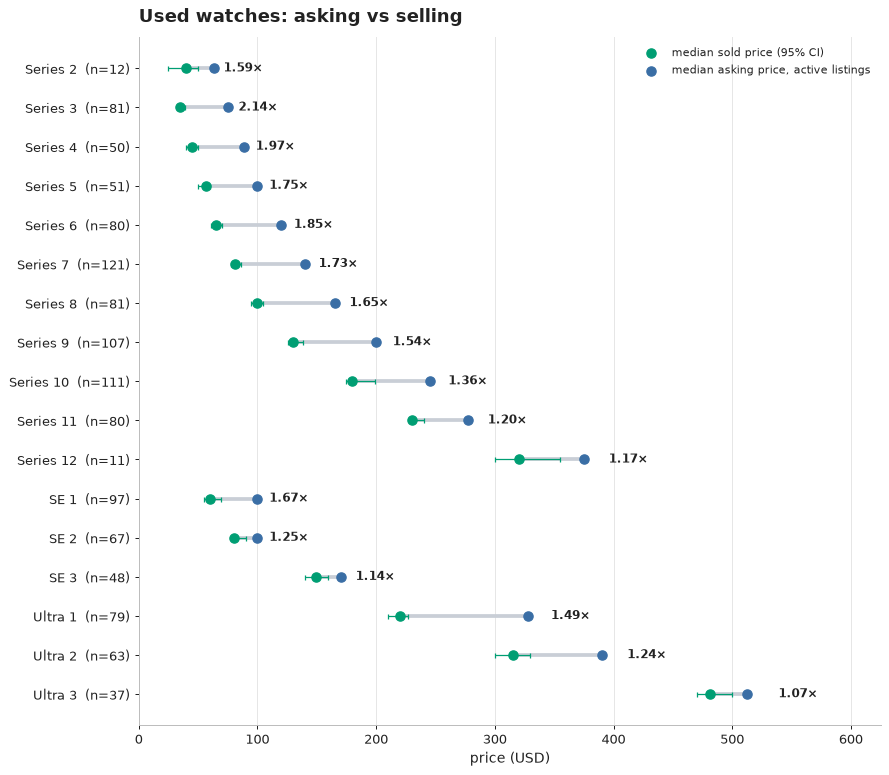

In [6]:
display(r["ask_used"].round(2))
V.fig_ask_vs_sold(r["ask_used"], "Used watches: asking vs selling")

In [7]:
display(r["ask_new"].round(2))

,model,n_ask,n_sold,ask,sold,sold_lo,sold_hi,ratio,ratio_lo,ratio_hi
0,Series 9,205,14,359.49,237.98,200.00,250.00,1.51,1.40,1.80
1,Series 10,163,14,360.00,275.00,249.99,289.50,1.31,1.23,1.46
2,Series 11,178,26,386.09,313.96,299.00,327.50,1.23,1.17,1.31
3,Series 12,95,24,614.93,389.99,379.99,407.34,1.58,1.48,1.81
4,SE 3,109,28,249.00,200.00,197.50,220.00,1.25,1.10,1.27
5,Ultra 3,126,10,690.00,595.18,544.50,669.97,1.16,1.03,1.27


### Back to Part I

,model,part1_mean_ask,part1_median_ask,part1_n,part1_gold_share,part1_mean_ask_no_gold,part2_median_sold,part2_n_sold,part2_median_ask,part2_n_ask
0,Series 2,743.38,699.00,25,0.88,615.00,49.99,15,56.51,639
1,Series 4,676.23,699.00,43,0.51,549.95,49.99,63,85.00,1396
2,Series 3,664.19,692.00,38,0.42,574.81,35.00,101,65.00,3209
3,Ultra 3,651.42,649.00,341,0.00,651.42,499.99,65,549.99,617
4,Series 5,623.62,550.00,49,0.29,535.56,59.00,59,100.00,1632
5,Series 0,591.49,569.98,17,0.00,591.49,40.00,4,50.00,296
6,Series 6,577.85,500.00,118,0.14,526.10,65.50,120,115.00,1972
7,Series 7,570.98,500.00,129,0.09,534.77,89.25,162,144.99,1999
8,Series 11,569.34,550.00,186,0.00,569.34,259.50,167,309.99,852
9,Ultra 2,569.00,530.00,562,0.00,569.00,325.00,100,449.48,1128


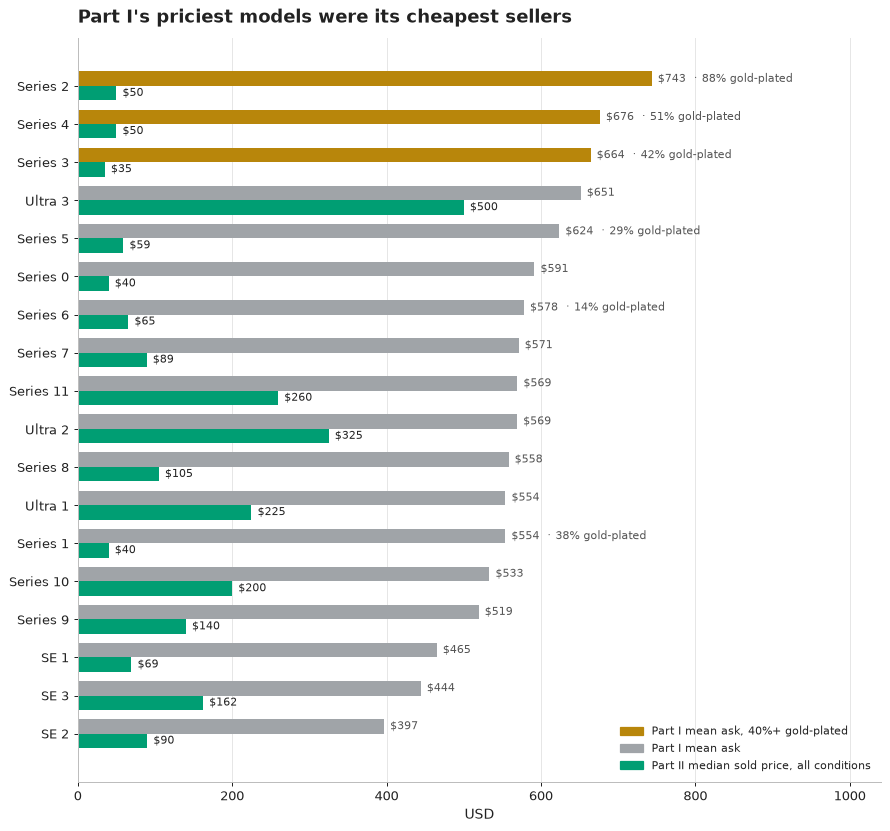

In [8]:
display(r["bridge"].round(2))
V.fig_part1_bridge(r["bridge"])

## 4. Priced right, sold fast (Kaplan–Meier)

2,312 new fixed-price listings, 461 sales, log-rank p = 8.7e-49, overall sold by 72 h 20.7%, ended without a known outcome (censored) 247


,position,n,events,sold_24h,sold_24h_lo,sold_24h_hi,sold_72h,sold_72h_lo,sold_72h_hi,sold_120h,sold_120h_lo,sold_120h_hi
0,Below 90%,337,122,0.284,0.236,0.340,0.406,0.349,0.468,0.469,0.404,0.540
1,90–110%,714,210,0.165,0.138,0.197,0.302,0.265,0.343,0.392,0.348,0.441
2,110–150%,761,97,0.059,0.044,0.079,0.131,0.106,0.161,0.171,0.140,0.208
3,Above 150%,500,32,0.033,0.020,0.054,0.069,0.047,0.099,0.083,0.058,0.119


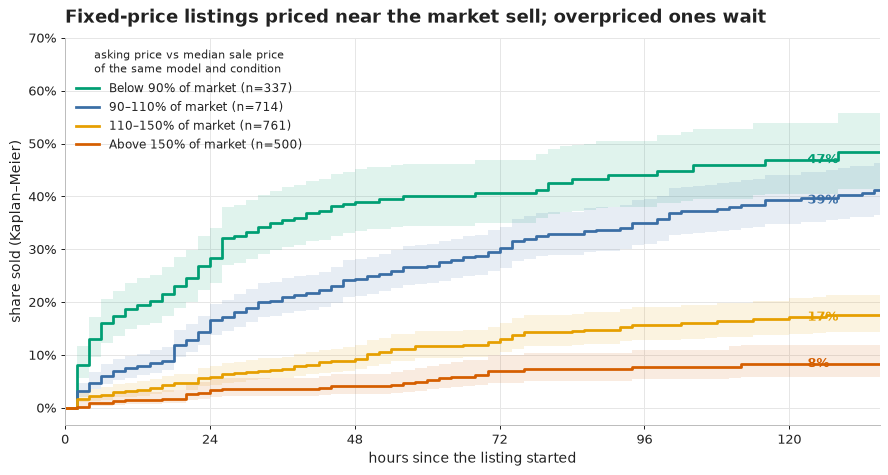

In [9]:
s = r["survival"]
print(f"{s['n']:,} new fixed-price listings, {s['events']} sales, log-rank p = {s['logrank_p']:.2g}, "
      f"overall sold by 72 h {s['sold_72h']:.1%}, ended without a known outcome (censored) {s['ended_unknown']}")
display(s["table"].round(3))
V.fig_time_to_sale(s["curves"], s["table"])

## 5. The gold-plating pitfall, revisited

In [10]:
g = r["gold"]
keys = ["n", "kinds", "ended", "sold", "n_sellers", "top_seller_share", "top3_share", "formats", "gtc_share", "conditions",
        "median_ask", "ask_q1", "ask_q3", "median_age_years", "share_older_2y", "plated_n", "median_ask_ratio",
        "median_sold_ratio", "lifetime_n", "lifetime_never", "lifetime_total", "lifetime_per_year_median",
        "comp_n", "comp_never", "comp_per_year_median", "multi_qty_share"]
pd.Series({k: g[k] for k in keys})

n                                                                         299
kinds                       {'Gold-plated watch': 292, 'Anodized watch, 24...
ended                                                                       0
sold                                                                        0
n_sellers                                                                  10
top_seller_share                                                     0.722408
top3_share                                                           0.949833
formats                     {'Fixed price + Best Offer': 290, 'Fixed price...
gtc_share                                                                 1.0
conditions                  {'New': 163, 'Open box': 129, 'Used': 6, 'Refu...
median_ask                                                             1199.0
ask_q1                                                                 881.02
ask_q3                                                          

,model,n,median_ask,plain_ask,plain_sold
0,Series 1,6,667.0,49.0,40.0
3,Series 2,23,699.0,56.5,50.0
4,Series 3,14,782.0,65.0,35.0
5,Series 4,24,799.0,85.0,50.0
6,Series 5,16,899.0,100.0,59.0
7,Series 6,27,999.0,115.0,65.5
8,Series 7,40,1298.0,145.0,89.2
9,Series 8,32,1299.0,175.0,105.0
10,Series 9,53,1399.0,220.0,140.0
1,Series 10,6,3449.0,269.4,200.0


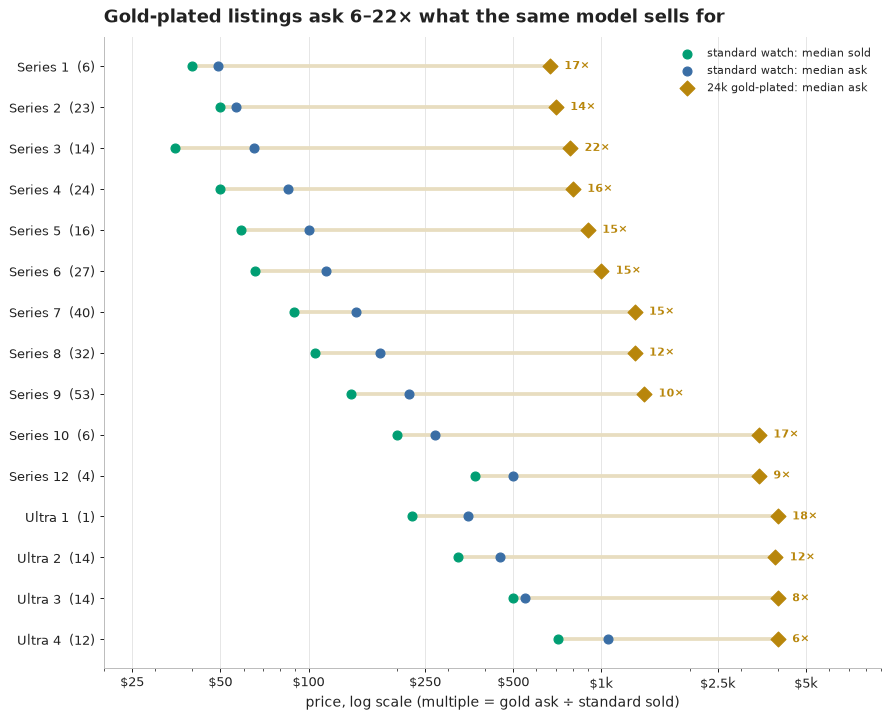

In [11]:
display(g["by_model"].round(1))
V.fig_gold_price_gap(g["by_model"])

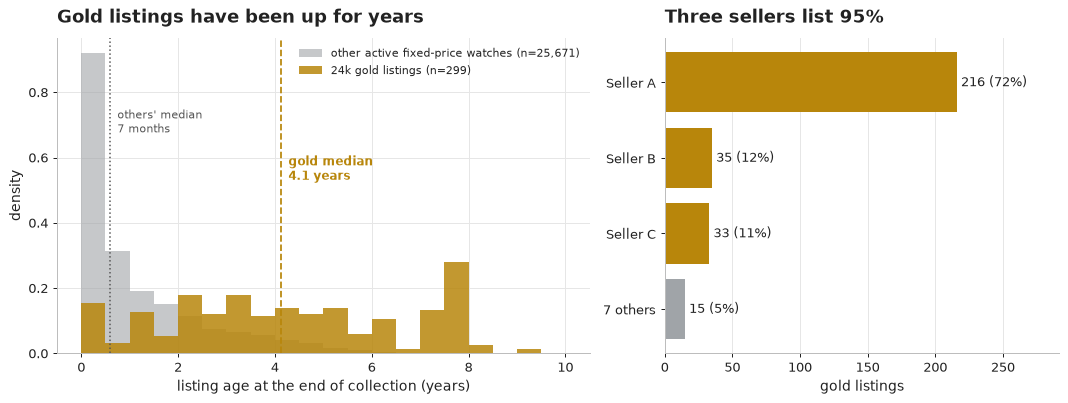

In [12]:
comp = d[(d["gold"] == 0) & (d["is_auction"] == 0) & (d["outcome"] == "active") & d["is_single_watch"]]
V.fig_gold_age(g, d[d["gold"] == 1], comp["age_years"].dropna())

Is zero sales in a week surprising? Compare with standard listings that look like the gold ones: fixed price,
New or Open box, the same models, and up for at least a year.

In [13]:
print(f"comparable listings: {g['window_comp_n']:,}, sold in the window: {g['window_comp_rate']:.2%}")
print(f"expected sales among {g['plated_n']} plated watches: {g['window_expected']:.1f}; P(0 sales) = {g['window_p_zero']:.3f}")
print(f"comparable listings priced at $500+: {g['window_pricey_k']} of {g['window_pricey_n']} sold")

comparable listings: 1,777, sold in the window: 1.07%
expected sales among 286 plated watches: 3.1; P(0 sales) = 0.046
comparable listings priced at $500+: 0 of 566 sold


## 6. What makes an auction sell

373 of 724 ended auctions sold (51.5%, 95% CI 47.9%–55.1%)
Series 9/10 vs Series 3: {'p1': 0.63, 'p2': 0.3562, 'diff': 0.2738, 'lo': 0.1233, 'hi': 0.4073, 'p': 0.0004, 'n1': 100.0, 'n2': 73.0, 'k1': 63.0, 'k2': 26.0}
free vs paid shipping (raw): {'p1': 0.6161, 'p2': 0.4959, 'diff': 0.1202, 'lo': 0.0196, 'hi': 0.2137, 'p': 0.0234, 'n1': 112.0, 'n2': 611.0, 'k1': 69.0, 'k2': 303.0}
feedback trend: {'coef': 0.21351814667484728, 'p': 0.00018833170950496454, 'n': 724}


,or_,lo,hi,p
free,1.105,0.686,1.781,0.682
log_fb,1.240,1.097,1.401,0.001
new_gen,1.761,1.237,2.509,0.002


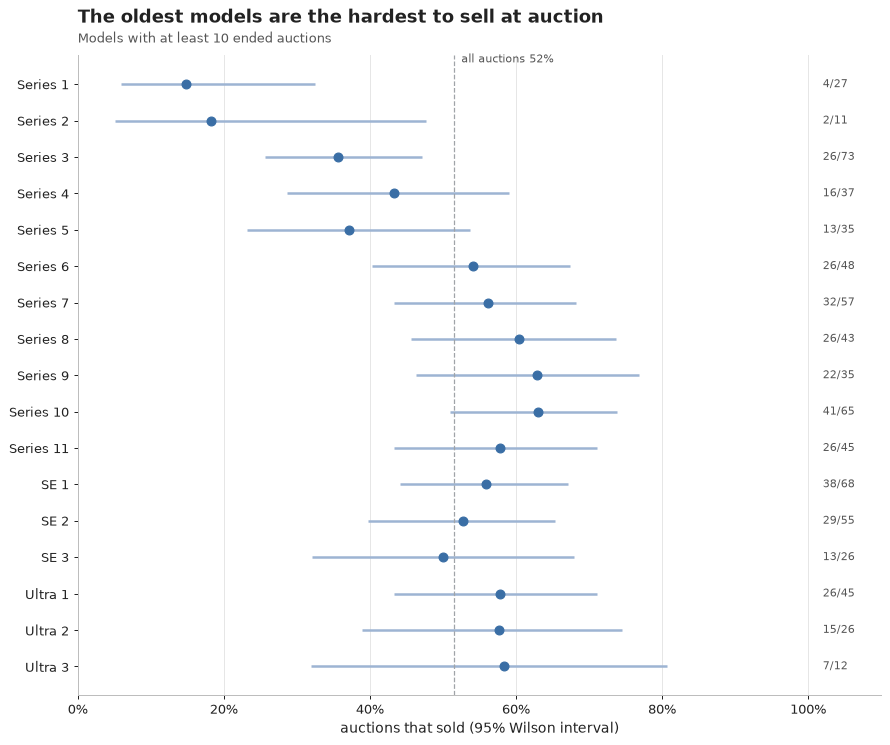

In [14]:
au = r["auctions"]
print(f"{au['k']} of {au['n']} ended auctions sold ({au['rate']:.1%}, 95% CI {au['ci'][0]:.1%}–{au['ci'][1]:.1%})")
print("Series 9/10 vs Series 3:", {k: round(float(v), 4) for k, v in au["new_vs_s3"].items()})
print("free vs paid shipping (raw):", {k: round(float(v), 4) for k, v in au["free_shipping"].items()})
print("feedback trend:", au["feedback_trend"])
display(pd.DataFrame(au["adjusted"]).T.round(3))
V.fig_rate_by_model(au["by_model"], au["rate"])

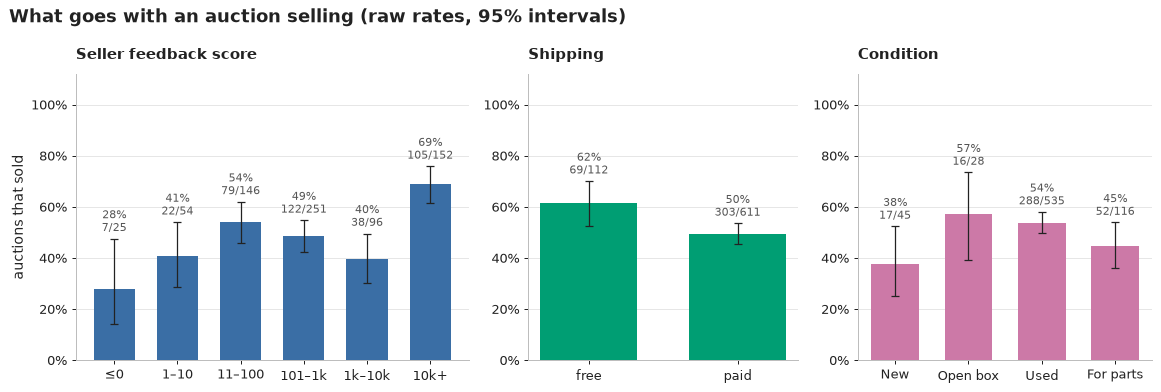

In [15]:
V.fig_sale_drivers(au)

Two listing fields leak the outcome and are kept out of the auction analysis. The database keeps the latest
value of each field, and eBay removes Best Offer and Buy It Now from an auction once it receives a bid, so
auctions still showing those options are mostly ones that never got a bid. The seller's listing count leaks
through relisting: unsold auctions are often relisted, which raises the count.

In [16]:
print("Best Offer still on:", {k: round(float(v), 3) for k, v in au["leak_best_offer"].items()},
      "mean final bids", round(au["leak_best_offer_mean_bids"], 2))
print("Buy It Now still on:", {k: round(float(v), 3) for k, v in au["leak_bin"].items()})
au["by_seller_listings"].round(3)

Best Offer still on: {'p1': 0.041, 'p2': 0.635, 'diff': -0.594, 'lo': -0.638, 'hi': -0.533, 'p': 0.0, 'n1': 146.0, 'n2': 578.0, 'k1': 6.0, 'k2': 367.0} mean final bids 0.04
Buy It Now still on: {'p1': 0.416, 'p2': 0.546, 'diff': -0.13, 'lo': -0.212, 'hi': -0.045, 'p': 0.003, 'n1': 173.0, 'n2': 551.0, 'k1': 72.0, 'k2': 301.0}


,seller_listings,k,n,rate,lo,hi
0,1,204,251,0.813,0.760,0.856
1,2–3,46,268,0.172,0.131,0.221
2,4–10,30,59,0.508,0.384,0.632
3,11+,93,146,0.637,0.556,0.711


### Auction prices are set late

373 sold auctions; final vs last bid seen in the final 15 minutes: median +3.3% (95% CI 1.6%–6.2%, n=197); still rose: 59%


,bin,median,q1,q3,n
0,0–15 min,0.968,0.792,1.000,197
1,15 min–1 h,0.917,0.717,1.000,251
2,1–3 h,0.902,0.675,1.000,295
3,3–6 h,0.867,0.616,0.987,275
4,6–12 h,0.833,0.587,0.969,250
5,12–24 h,0.809,0.494,0.954,255
6,24–48 h,0.755,0.471,0.943,265
7,48–72 h,0.707,0.432,0.945,198
8,72 h+,0.615,0.368,0.948,161


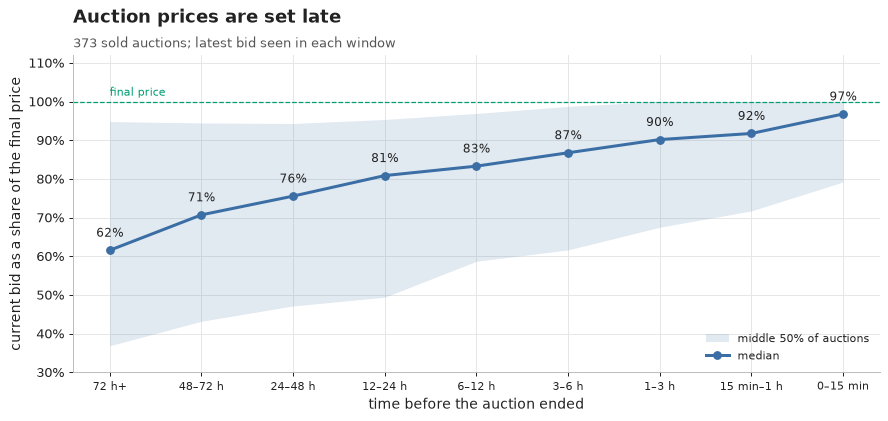

In [17]:
tr = r["trajectories"]
print(f"{tr['n_auctions']} sold auctions; final vs last bid seen in the final 15 minutes: median +{tr['late_median_jump']:.1%} "
      f"(95% CI {tr['late_jump_ci'][0]:.1%}–{tr['late_jump_ci'][1]:.1%}, n={tr['late_n']}); still rose: {tr['late_rose_share']:.0%}")
display(tr["table"].round(3))
V.fig_trajectory(tr["table"], tr)

### Fixed-price endings, repricing and sellers

In [18]:
fx = r["fixed"]
print(f"fixed-price endings: {fx['k']:,} of {fx['n']:,} recorded a sale ({fx['rate']:.1%}); free vs paid shipping "
      f"{fx['free_shipping']['p1']:.1%} vs {fx['free_shipping']['p2']:.1%} (p = {fx['free_shipping']['p']:.2f})")
display(fx["by_format"].round(3))
print("repricing:", r["repricing"])
print("seller concentration:", r["sellers"])

fixed-price endings: 1,593 of 2,875 recorded a sale (55.4%); free vs paid shipping 54.8% vs 56.3% (p = 0.43)


,format,k,n,rate,lo,hi
0,Fixed price,898,1636,0.549,0.525,0.573
1,Fixed price + Best Offer,695,1239,0.561,0.533,0.588


repricing: {'n': 26571, 'changed': 0.0977757705769448, 'cut': 0.07636144669000038, 'raised': 0.018704602762410146, 'median_cut': -0.05664150943396218}
seller concentration: {'n_sellers': 20109, 'top10_listing_share': 0.07368721823607847, 'top10_sales_share': 0.10567135239941833, 'single_listing_sellers': 17787, 'largest': 341}


## 7. Will this auction sell? CatBoost classifier

Sample: ended single-watch auctions first observed before their first bid, so the opening bid is known.
Features are what a seller sets at listing time. `start_vs_market` is the opening bid divided by the median
fixed-price sale for the same model and condition. Validation is 5-fold `StratifiedGroupKFold` by seller, against
a logistic regression on the same inputs. A nested Platt scaling step is recorded but not used, because it did
not improve the Brier score.

In [19]:
sm = r["sale_model"]
pd.Series({k: v for k, v in sm["metrics"].items() if not isinstance(v, dict)})

n                                                             525
events                                                        185
base_rate                                                0.352381
sellers                                                       387
auc                                                       0.68961
auc_ci                   (0.6452718973486666, 0.7338774183113292)
auc_folds       [0.6294555424990208, 0.763023893458676, 0.6373...
auc_logit                                                0.590612
auc_logit_ci             (0.5415270417912219, 0.6387177114977743)
brier                                                    0.215726
brier_cal                                                0.216929
auc_cal                                                   0.68527
brier_logit                                              0.256691
brier_base                                               0.228209
logloss                                                  0.621109
dtype: obj

,predicted,observed,n,lo,hi
0,0.154,0.105,105,0.060,0.178
1,0.250,0.257,105,0.183,0.348
2,0.331,0.381,105,0.294,0.476
3,0.453,0.467,105,0.374,0.562
4,0.701,0.552,105,0.457,0.644


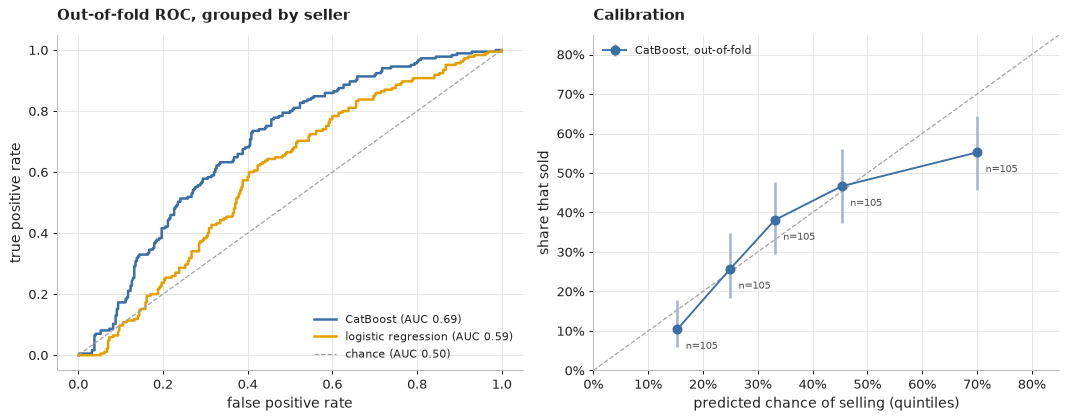

In [20]:
display(pd.DataFrame(sm["reliability"]).round(3))
V.fig_sale_validation(sm)

start_vs_market          0.410
seller_feedback_score    0.261
model                    0.133
duration_days            0.101
end_hour                 0.094
case_size                0.093
end_weekend              0.072
shipping_cost            0.071
condition_group          0.041
seller_feedback_pct      0.020
image_count              0.008
cellular                 0.004
returns_accepted         0.003
has_reserve              0.001
free_shipping            0.000
top_rated_buying         0.000
dtype: float64

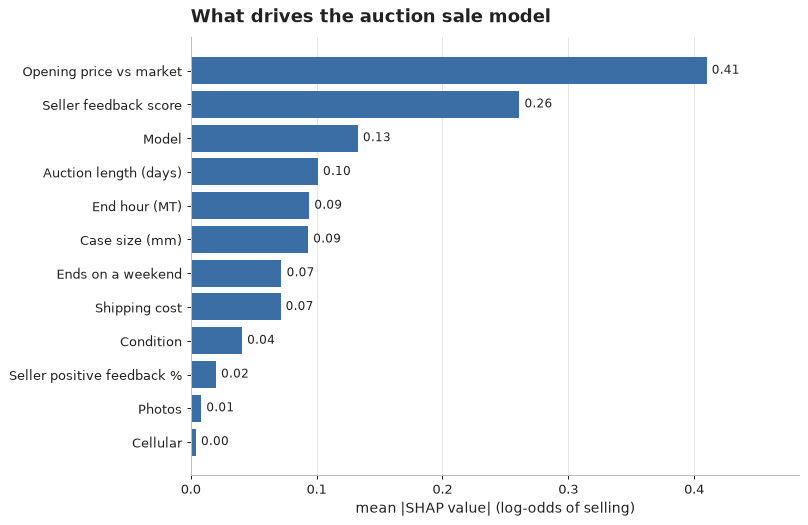

In [21]:
display(sm["importance"].round(3))
V.fig_importance(sm["importance"], "What drives the auction sale model", "{:.2f}", xlabel="mean |SHAP value| (log-odds of selling)")

,ratio,prob
0,0.25,0.476
1,0.50,0.454
2,0.75,0.411
3,0.90,0.377
4,1.00,0.365
5,1.10,0.351
6,1.25,0.322
7,1.50,0.268
8,2.00,0.245
9,3.00,0.213


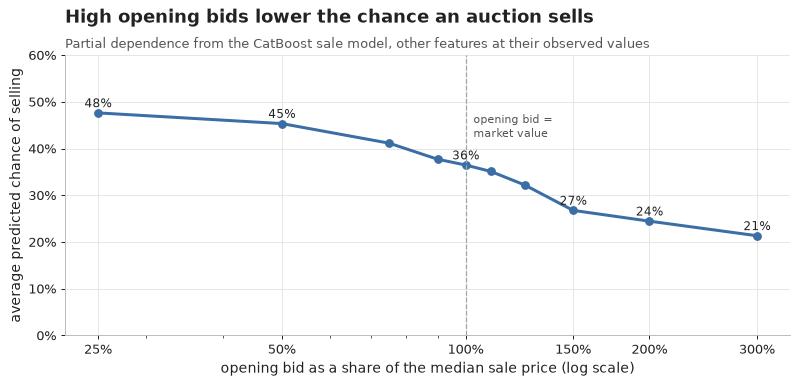

In [22]:
display(pd.DataFrame(sm["partial"]).round(3))
V.fig_opening_price(sm["partial"])

## 8. What does a watch sell for? CatBoost regressor with SHAP

Sample: sold single watches (non-gold, final price not a robust outlier). Validation is 5-fold `GroupKFold` by seller,
against a model-and-condition median baseline computed inside each training fold.

In [23]:
pm = r["price_model"]
pd.Series(pm["metrics"])

n              1873.000000
sellers        1196.000000
r2                0.903372
mae              28.175891
median_ae        19.380545
r2_base           0.868290
mae_base         28.990561
mape_median       0.147181
dtype: float64

model                    53.15
condition_group          30.47
material                 19.72
case_size                16.28
titanium                 11.47
format                    4.75
seller_feedback_score     2.48
premium_band              1.33
shipping_cost             1.16
free_shipping             0.84
seller_listings           0.77
cellular                  0.70
detail                    0.59
image_count               0.34
hermes                    0.27
us_location               0.01
returns_accepted          0.01
top_rated_buying          0.00
dtype: float64

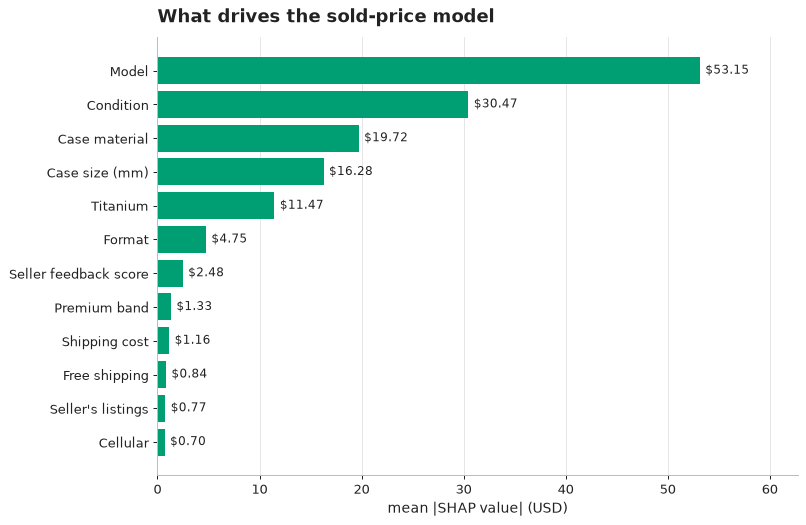

In [24]:
display(pm["importance"].round(2))
V.fig_importance(pm["importance"], "What drives the sold-price model", "${:,.2f}", color=V.SOLD, xlabel="mean |SHAP value| (USD)")

,mean,size
format,,
Auction,-13.79,307
Fixed price,3.72,886
Fixed price + Best Offer,2.02,680


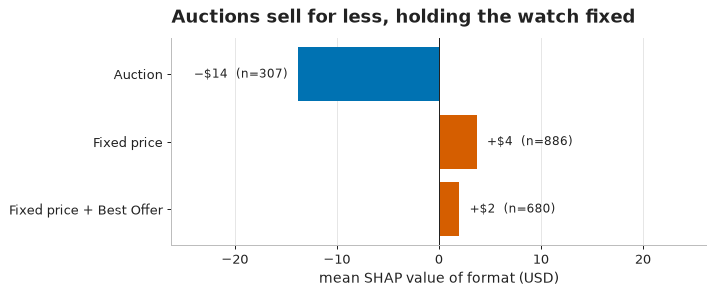

In [25]:
display(pm["format_shap"].round(2))
V.fig_format_effect(pm["format_shap"])

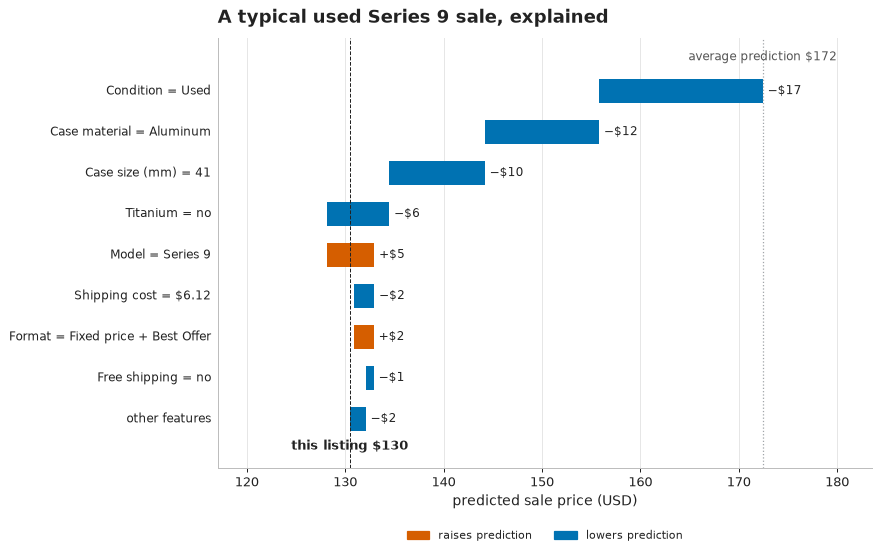

In [26]:
sys.path.insert(0, str(ROOT / "scripts"))
from make_figures import example_index, row_values
i = example_index(pm["frame"], pm["X"], "Series 9", "Used")
V.fig_waterfall(pm["expected"], pm["shap"].loc[i], row_values(pm["X"], i), "A typical used Series 9 sale, explained")

## 9. Summary

1. Asking prices overstate what old watches sell for: a used Series 3 asks 2.1× its median sale price; an Ultra 3, 1.07×.
2. Price relative to the going rate drives how fast a fixed-price listing sells.
3. None of the 299 gold listings sold in the week; they ask several times what the same model sells for. A week is
   short for listings this slow, so this suggests rather than proves that the prices do not clear.
4. Newer models and sellers with more feedback sell more of their auctions; free shipping has no effect after
   adjustment.
5. Most of an auction's price arrives in its last day.
6. Model and condition set the sale price; auctions sell for about $14 less than the same watch at a fixed price.